# Iris：从花朵尺寸到品种

输入四个尺寸，输出 setosa、versicolor、virginica 三类得分。
本例使用本地 `data/iris.csv`。请在 `examples` 目录运行，按顺序执行单元格。

In [3]:
import csv
from statistics import mean, pstdev

from qutai import nn, visualization

## 1. 看懂数据

每行依次是花萼长、花萼宽、花瓣长、花瓣宽，单位 cm；最后一列是品种。
类别编号为 0、1、2。表格各取一个品种，先把输入与目标对应起来。

In [4]:
features = ["花萼长", "花萼宽", "花瓣长", "花瓣宽"]
names = ["setosa", "versicolor", "virginica"]
with open("data/iris.csv", newline="", encoding="utf-8") as file:
    rows = list(csv.reader(file))[1:]
inputs = [[float(value) for value in row[:4]] for row in rows]
targets = [names.index(row[4]) for row in rows]
visualization.Table([inputs[targets.index(index)] + [name] for index, name in enumerate(names)], columns=features + ["品种"])

花萼长,花萼宽,花瓣长,花瓣宽,品种
5.1,3.5,1.4,0.2,setosa
7.0,3.2,4.7,1.4,versicolor
6.3,3.3,6.0,2.5,virginica


## 2. 留出测试数据，再统一尺度

每类随机取 40 朵训练、10 朵测试，共 120 / 30。测试花朵不参与训练。
标准化是 `(数值 − 均值) / 标准差`；均值和标准差只从训练集计算，新花朵也用同一组数。

In [6]:
train_indices, test_indices = [], []
for target in range(3):
    indices = [index for index, value in enumerate(targets) if value == target]
    train_indices.extend(indices[:40])
    test_indices.extend(indices[40:])
raw_inputs = [inputs[index] for index in train_indices]
test_samples = [inputs[index] for index in test_indices]
test_targets = [targets[index] for index in test_indices]
targets = [targets[index] for index in train_indices]
means = [mean(column) for column in zip(*raw_inputs)]
scales = [pstdev(column) for column in zip(*raw_inputs)]


In [7]:
def normalize(data):
    return [[(value - average) / scale for value, average, scale in zip(row, means, scales)] for row in data]

inputs = normalize(raw_inputs)
test_inputs = normalize(test_samples)
print("同一朵花：", raw_inputs[0], "→", inputs[0])

同一朵花： [5.1, 3.5, 1.4, 0.2] → [-0.93784375010451, 0.984532619151131, -1.3406326570559806, -1.316851962589816]


## 3. 搭建并训练模型

`4 → 16 → 3`：四个尺寸经过隐藏层，变成三个类别得分。
交叉熵直接接收得分和整数类别。每一步都显式执行清梯度、计算损失、反向传播、更新参数。
`seed` 仅用于复现这份示例，可以删除。

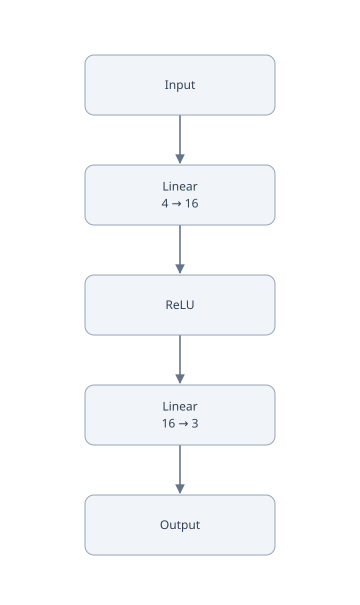

In [10]:
model = nn.Model([
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3),
])
optimizer = nn.SGD(model, learning_rate=0.1)
loss_function = nn.CrossEntropy()
visualization.Network(model)

In [11]:
for step in range(501):
    optimizer.zero_grad()
    loss = loss_function(model(inputs), targets)
    loss.backward()
    optimizer.step()

    if step % 100 == 0: print(f"step {step}  loss {loss.item():.6f}")

step 0  loss 0.990860
step 100  loss 0.263110
step 200  loss 0.157943
step 300  loss 0.110327
step 400  loss 0.089104
step 500  loss 0.077559


## 4. 用没有训练过的花朵测试

`train=False` 使用预测状态。每行最大得分的位置就是预测类别，直接用 `argmax(axis=-1)` 选择。

In [13]:
scores = model(test_inputs, train=False)
predictions = scores.argmax(axis=-1)
correct = sum(prediction == target for prediction, target in zip(predictions, test_targets))
print(f"测试准确率：{correct}/{len(test_targets)} = {correct / len(test_targets):.1%}")
visualization.Table([sample + [names[target], names[prediction]] for sample, target, prediction in zip(test_samples[:4], test_targets[:4], predictions[:4])], columns=features + ["正确", "预测"])

测试准确率：30/30 = 100.0%


花萼长,花萼宽,花瓣长,花瓣宽,正确,预测
5.0,3.5,1.3,0.3,setosa,setosa
4.5,2.3,1.3,0.3,setosa,setosa
4.4,3.2,1.3,0.2,setosa,setosa
5.0,3.5,1.6,0.6,setosa,setosa


## 5. 自己输入两朵花

修改下面的四个尺寸。需要查看概率时才使用 Softmax；它不改变最大得分所在的位置。

In [19]:
samples = [[5.1, 3.5, 1.4, 0.2], [1.2, 3.4, 5.6, 7.8]]
softmax = nn.Softmax()
probabilities = softmax(model(normalize(samples), train=False))
visualization.Table(probabilities.tolist(), columns=names, title="这朵花属于各品种的概率")

setosa,versicolor,virginica
0.9988160817874656,0.001168933810170025,1.498440236445744e-05
8.999190260506136e-15,1.6027844039292946e-14,0.9999999999999749
